In [1]:
import sys, os; sys.path.append(os.path.join(os.path.dirname("plot_distances.ipynb"), '..'))

from siamese.models.mobilenet_v3_large import model
from siamese.dataset.data_loader import data_loader
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np
import torch
import csv

In [2]:
PKLOT_SIAMESE_PATH = "../siamese/_models/cnrparkext_plds_to_pklot_dea6f/model_cnrparkext_plds_5c4be.pt"
PKLOT_DATASET_CONFIG = {
                        "train": [
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT",
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds"    
                        ],
                        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
                        "split": 0.7,
                        "full_difficult": True,
                        "img_size": [128, 128]
                    }

CNRPARK_SIAMESE_PATH = "../siamese/_models/pklot_plds_to_cnrparkext_b5d8f/model_pklot_plds_01e83.pt"
CNRPARK_DATASET_CONFIG = {
                        "train": [
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds"
                        ],
                        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT",
                        "split": 0.7,
                        "full_difficult": True,
                        "img_size": [128, 128]
                    }

PLDS_SIAMESE_PATH = "../siamese/_models/pklot_cnrparkext_to_plds_a404f/model_pklot_cnrparkext_2da05.pt"
PLDS_DATASET_CONFIG = {
                        "train": [
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PKLot",
                            "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/CNRParkEXT"
                        ],
                        "test": "/home/tteuz/Desktop/mestrado/meta_pklot/datasets/siamese/PLds",
                        "split": 0.7,
                        "full_difficult": True,
                        "img_size": [128, 128]
                    }

MODEL_CONFIG = { "optimizer": "Adam", "device": "cuda:0" }

In [3]:
def print_histogram(subset, distances):
    dist_array = np.array(distances)
    min_val, max_val = dist_array.min(), dist_array.max()

    bins = np.arange(start=np.floor(min_val * 20) / 20, 
                     stop=np.ceil(max_val * 20) / 20 + 0.03, 
                     step=0.03)

    plt.figure(figsize=(8, 6))
    plt.hist(dist_array, bins=bins, color='skyblue', edgecolor='black')

    plt.xlim(bins[0], bins[-1])
    plt.grid(True, axis='y', linestyle='--', alpha=0.7)

    plt.title(f'Distances for {subset} - Pairs qty: {len(distances)}')
    plt.xlabel('Distance')
    plt.ylabel('Frequency')

    plt.savefig(f"temp/{subset}.png")
    plt.show()

In [4]:
def save_csv(subset, labels, distances):
    with open(f"temp/{subset}.csv", mode='w', newline='') as file:
        writer = csv.writer(file, delimiter=';')

        for distance, label in zip(distances, labels):
            writer.writerow([distance, label])

### PKLot

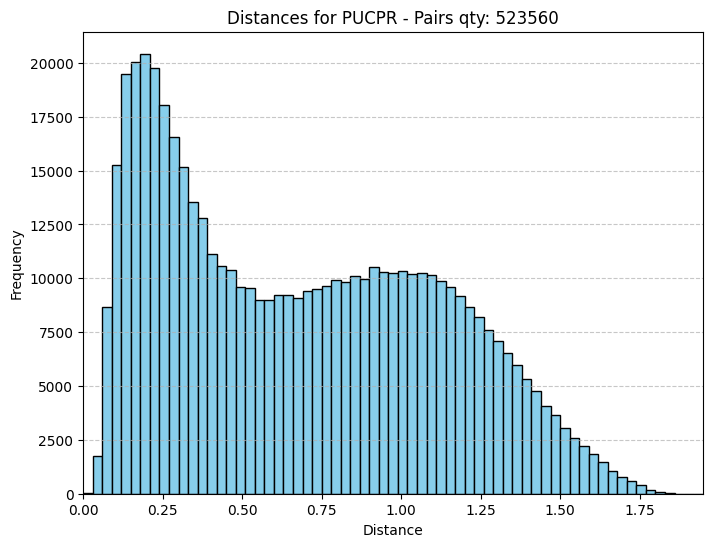

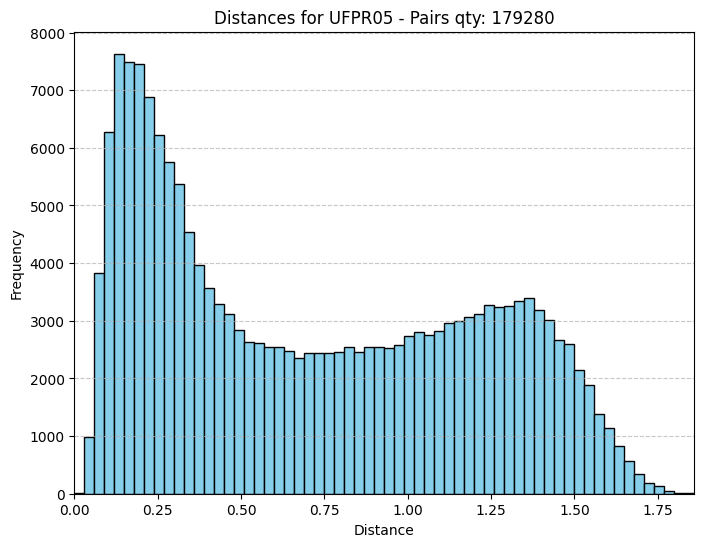

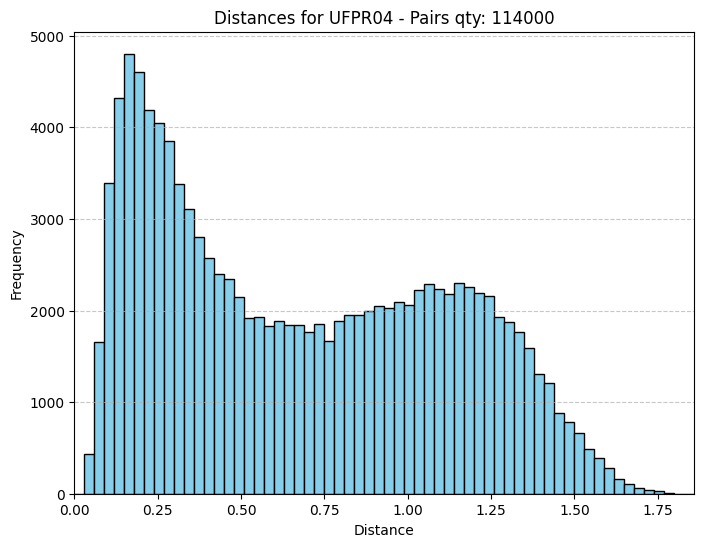

In [5]:
test_model = model(pre_trained=False, config=MODEL_CONFIG)
test_model.load_state_dict(torch.load(PKLOT_SIAMESE_PATH, map_location=MODEL_CONFIG["device"]))

ds_loader = data_loader(PKLOT_DATASET_CONFIG)

all_distances, all_labels = defaultdict(list), defaultdict(list)
for _ in range(15):
    test_subsets = ds_loader.get_test_subsets()
    for subset, images in test_subsets.items():
        test_loader = torch.utils.data.DataLoader(images, batch_size=500, shuffle=False, num_workers=8, pin_memory=True)
        
        distances, labels = test_model.predict_distances(test_loader)
        all_distances[subset].extend(distances)
        all_labels[subset].extend(labels)
    
for subset, distances in all_distances.items():
    print_histogram(subset, distances)
    save_csv(subset, all_labels[subset], distances)

### CNRParkEXT

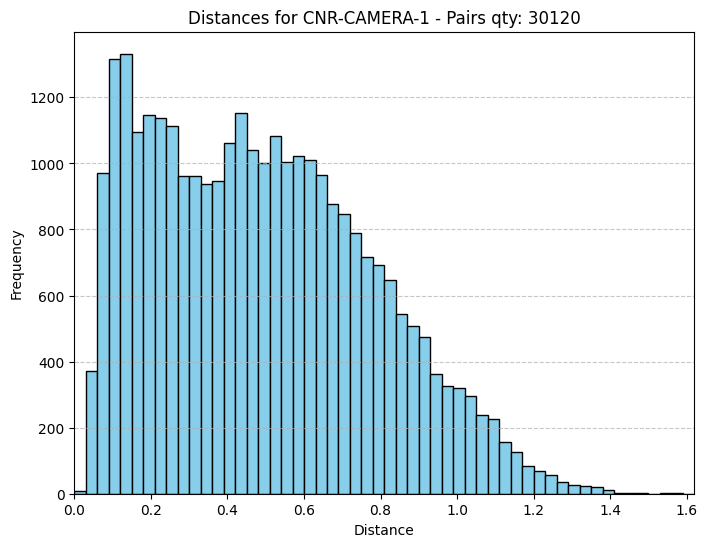

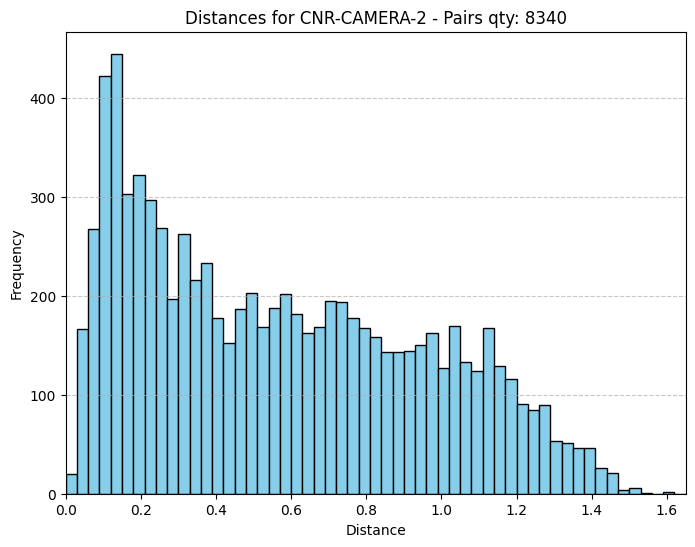

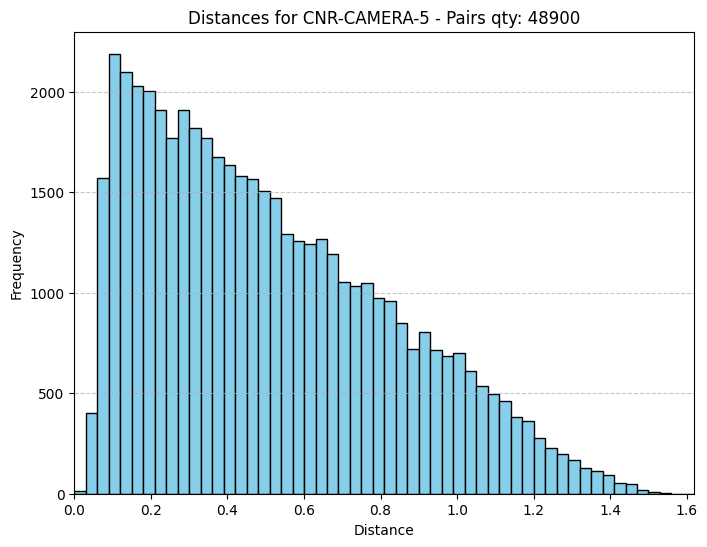

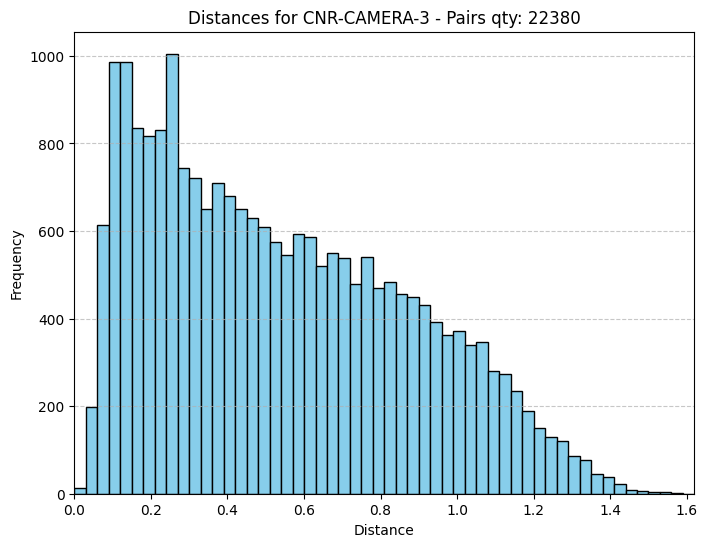

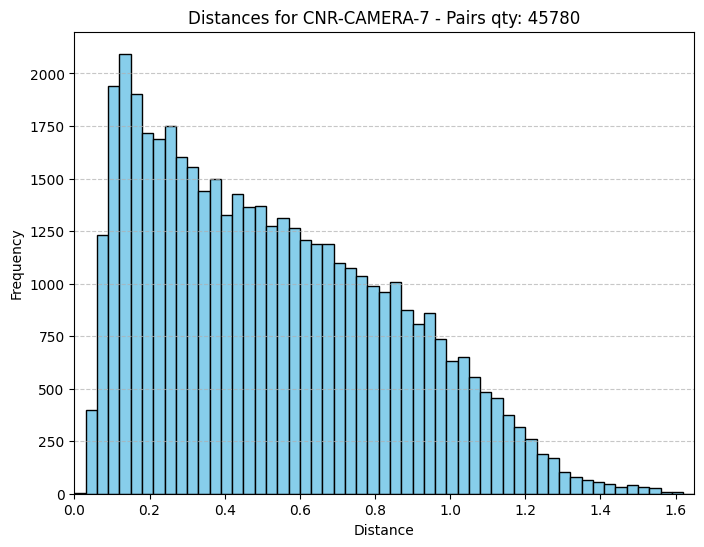

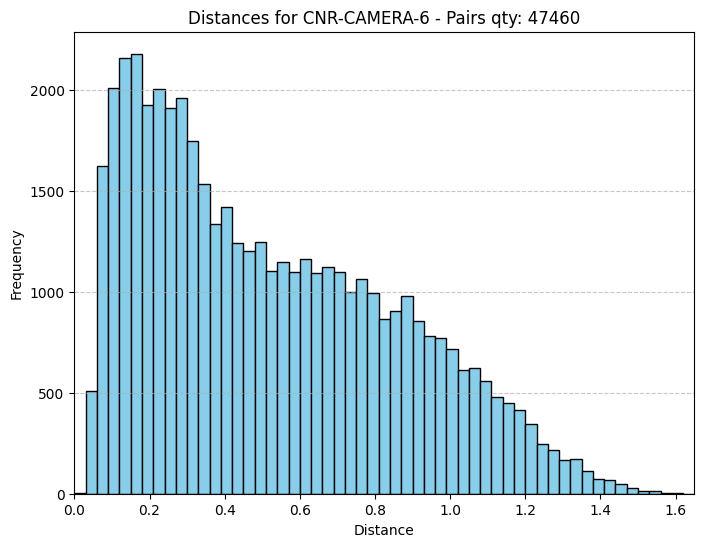

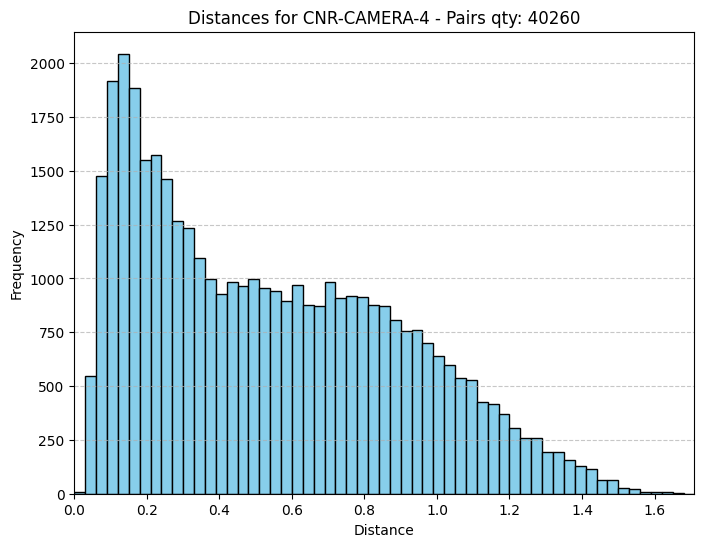

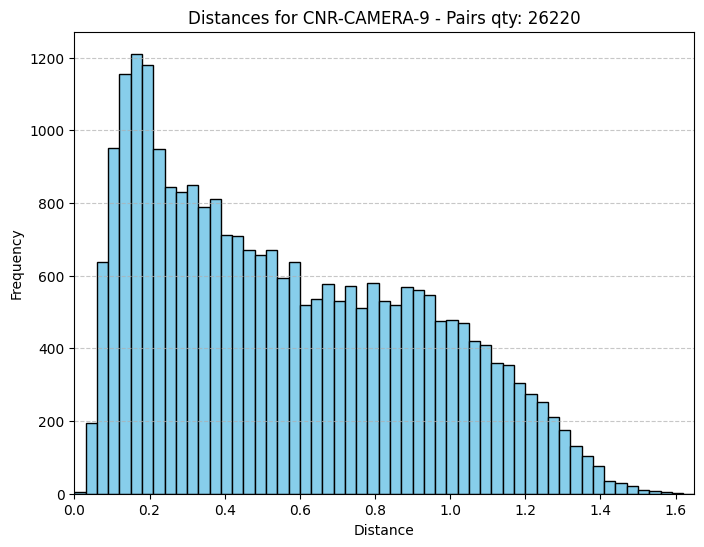

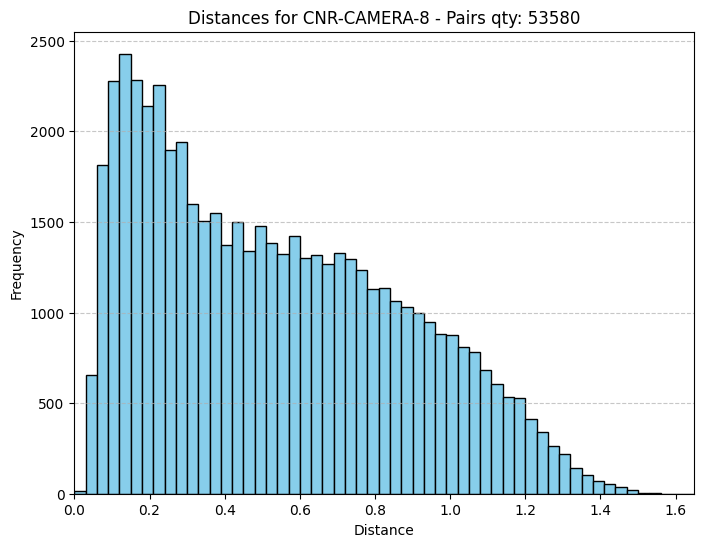

In [6]:
test_model = model(pre_trained=False, config=MODEL_CONFIG)
test_model.load_state_dict(torch.load(CNRPARK_SIAMESE_PATH, map_location=MODEL_CONFIG["device"]))

ds_loader = data_loader(CNRPARK_DATASET_CONFIG)

all_distances, all_labels = defaultdict(list), defaultdict(list)
for _ in range(15):
    test_subsets = ds_loader.get_test_subsets()
    for subset, images in test_subsets.items():
        test_loader = torch.utils.data.DataLoader(images, batch_size=500, shuffle=False, num_workers=8, pin_memory=True)
        
        distances, labels = test_model.predict_distances(test_loader)
        all_distances[subset].extend(distances)
        all_labels[subset].extend(labels)
    
for subset, distances in all_distances.items():
    print_histogram(subset, distances)
    save_csv(subset, all_labels[subset], distances)

### PLds

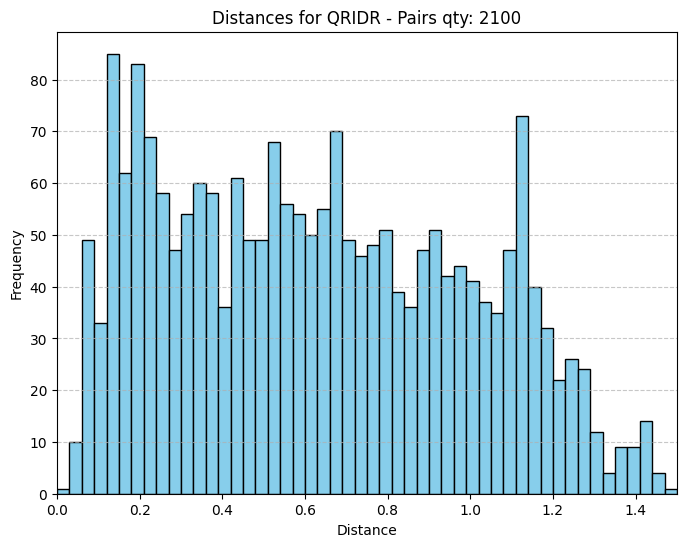

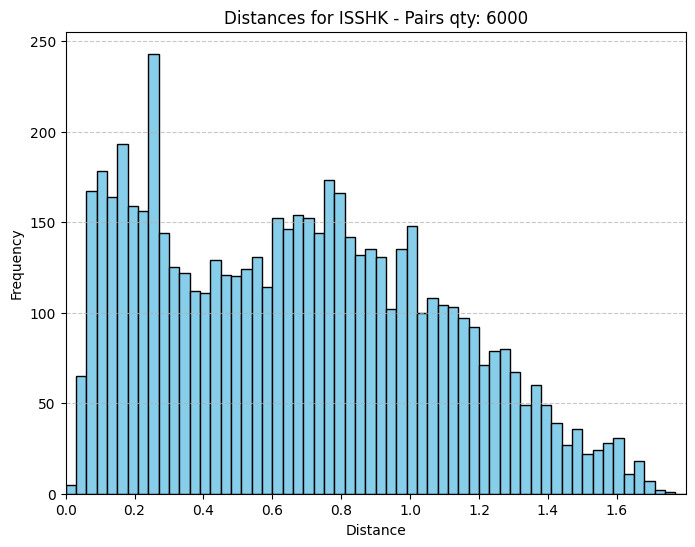

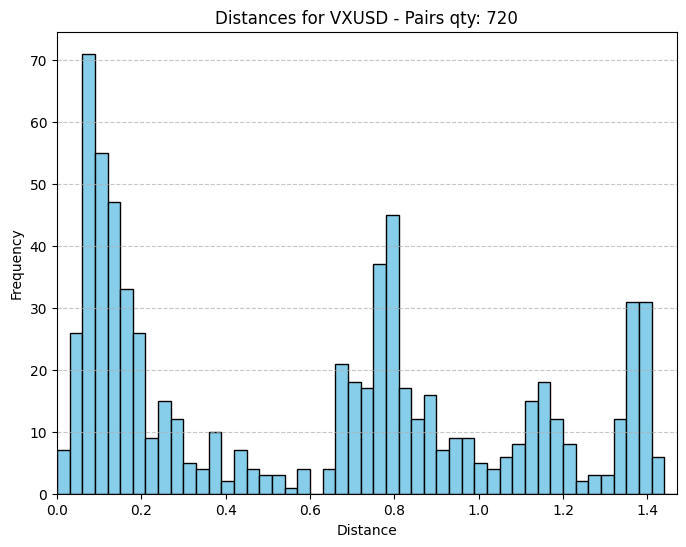

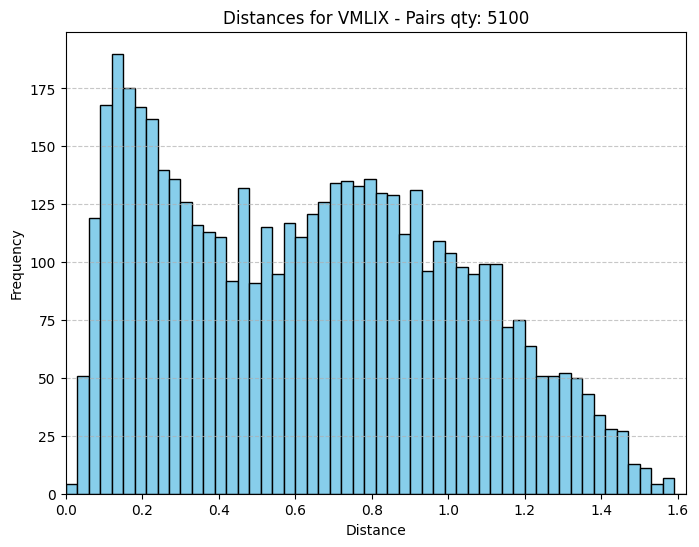

In [7]:
test_model = model(pre_trained=False, config=MODEL_CONFIG)
test_model.load_state_dict(torch.load(PLDS_SIAMESE_PATH, map_location=MODEL_CONFIG["device"]))

ds_loader = data_loader(PLDS_DATASET_CONFIG)

all_distances, all_labels = defaultdict(list), defaultdict(list)
for _ in range(15):
    test_subsets = ds_loader.get_test_subsets()
    for subset, images in test_subsets.items():
        test_loader = torch.utils.data.DataLoader(images, batch_size=500, shuffle=False, num_workers=8, pin_memory=True)
        
        distances, labels = test_model.predict_distances(test_loader)
        all_distances[subset].extend(distances)
        all_labels[subset].extend(labels)
    
for subset, distances in all_distances.items():
    print_histogram(subset, distances)
    save_csv(subset, all_labels[subset], distances)